<a href="https://colab.research.google.com/github/majopalmeros/Inteligencia-Artificial-/blob/main/Practicas/Practica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import load_iris
iris = load_iris()


# Explicacion

cargamos el dataset load_iris que tare el conjunto de 150 flores, de 3 especies de iris (setosa,versicolor y virginica)
que tiene cuatro medidas que son: ancho,largo, pétalo y sepalo.

In [2]:
print(iris.keys())


dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


muestra que contiene el objeto los datos,nombre de fila, la descripción etc.


In [3]:
print(iris.DESCR)


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

imprime la ficha del dataset: su origen, las variables y sus rangos.

In [4]:
iris.target_names
iris.target
iris.data
iris.feature_names


['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

Revisa los atributos

In [5]:
import pandas as pd

iris_df = pd.DataFrame(data=iris['data'], columns=iris['feature_names'])
iris_df


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


se creo un dataframe y se pasan a una tabla con pandas para poder leerlos mas facil.

In [6]:
iris_df.describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Calcula la media,desviación el min y maximo


# **Preprocesamiento de datos**

In [7]:
X = iris_df
y = pd.get_dummies(iris.target).values


X= son las 4 medidas largo y ancho del sepalo y largo y ancho del pétalo
Y= Y es la especie convertida a formato one-hot.”
 one-hot significa que setosa =
  [1,0,0], versicolor = [0,1,0] y virginica = [0,0,1]. Se hace así porque la red tiene 3 salidas, una por especie.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, random_state=42
)


Por lo que entendi separamos 80% de los datos para entrenar 20% para probar
random_state hace que la división salga igual cada vez que ejecuta

In [9]:
print(X_train.shape)
print(X_test.shape)


(120, 4)
(30, 4)


Comprobamos que quedaron 120 flores para entrenar y 30 para probar y los dos tienen las 4 medidas


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Estandarizamos las medidas para que todas tengan media 0 y desviación 1.

# **Red neuronal multicapa**

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

modelo = Sequential([
    Dense(64, input_shape=(X_train.shape[1],), activation='relu'),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax'),
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Aquí armamos la red neuronal. Es una red multicapa, o sea, con varias capas una detrás de otra. La primera capa recibe las 4 medidas de la flor. Luego hay dos capas ocultas, una de 64 neuronas y otra de 32, que son donde la red piensa y encuentra patrones.


In [12]:
from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate)


Aquí elegimos cómo va a aprender la red

In [13]:
modelo.compile(
    optimizer=adam_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


Aquí dejamos lista la red para entrenar. Le decimos qué optimizador usar


# **Entrenar el modelo**

In [14]:
history = modelo.fit(
    X_train, y_train,
    epochs=10, batch_size=1,
    validation_data=(X_test, y_test)
)


Epoch 1/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7583 - loss: 0.7916 - val_accuracy: 0.9000 - val_loss: 0.5379
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - loss: 0.4807 - val_accuracy: 0.9000 - val_loss: 0.3256
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8417 - loss: 0.3644 - val_accuracy: 0.9333 - val_loss: 0.2334
Epoch 4/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8833 - loss: 0.2765 - val_accuracy: 0.9333 - val_loss: 0.1745
Epoch 5/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9167 - loss: 0.2247 - val_accuracy: 0.9333 - val_loss: 0.1637
Epoch 6/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9500 - loss: 0.1756 - val_accuracy: 1.0000 - val_loss: 0.1065
Epoch 7/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9500 - loss: 0.1367 - val_accuracy: 1.0000 - val_loss: 0.0753
Epoch 8/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9750 - loss: 0.1113 - val_accuracy: 1.

Aquí es donde la red aprende. Le damos las 120 flores de entrenamiento y las repasa 10 veces; cada repaso se llama época.

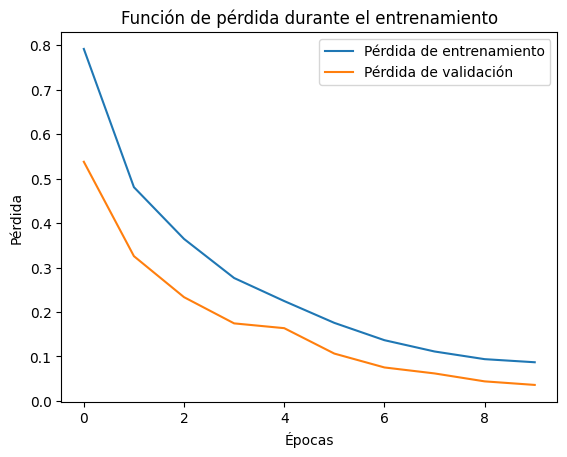

In [15]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()


Aquí graficamos cómo fue bajando el error durante el entrenamiento
Hay dos líneas: una para los datos de entrenamiento y otra para los de validación

In [16]:
loss, accuracy = modelo.evaluate(X_test, y_test)
print(f'Loss: {loss}, Accuracy: {accuracy}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 1.0000 - loss: 0.0361
Loss: 0.03606452792882919, Accuracy: 1.0


Aquí le hacemos el la prueba final a la red con las 30 flores que nunca vio durante el entrenamiento. Nos da dos resultados: la pérdida, que es qué tanto se equivocó, y la exactitud, que es el porcentaje de flores que clasificó bien

In [17]:
predictions = modelo.predict(X_test)
# Obtener el índice de la clase predicha para cada punto de datos
predicted_classes = np.argmax(predictions, axis=1)
# Obtenemos el índice de la clase real de y_test
actual_classes = np.argmax(y_test, axis=1)

comparison = pd.DataFrame({'Actual Class Index': actual_classes, 'Predicted Class Index': predicted_classes})
# Agregar columnas con los nombres reales y predichos de las flores utilizando iris.target_names
comparison['Actual Flower'] = [iris.target_names[i] for i in actual_classes]
comparison['Predicted Flower'] = [iris.target_names[i] for i in predicted_classes]
# Reordenar las columnas para una mejor visualización
comparison = comparison[['Actual Class Index', 'Actual Flower', 'Predicted Class Index', 'Predicted Flower']]
print(comparison.head())


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


NameError: name 'np' is not defined

Aquí le pedimos a la red que prediga la especie de cada flor de prueba.

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score

y_pred = model.predict(X_test)
# Convertir las predicciones a clases
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Calcular la matriz de confusión
cm = confusion_matrix(y_test_classes, y_pred_classes)
# Calcular la sensibilidad
sensitivity = recall_score(y_test_classes, y_pred_classes, average=None)


Aquí calculamos la matriz de confusión, que es una tabla que muestra en qué acertó la red y con qué especies se confundió

In [ ]:
# Visualizar la matriz de confusión como una imagen de colores
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap='Blues')

# Mostrar la sensibilidad (recall) para cada clase
print('Sensitivity (Recall) for each class:')
for i in range(3):
    print(f'Class {i}: {sensitivity[i]}')


Por último dibujamos la matriz de confusión para verla más fácil y mostramos la sensibilidad de cada especie.